# Логистическая регрессия — практика №2
## От простой модели к качественному классификатору

**Цель:** не просто обучить `LogisticRegression`, а понять, *почему модель ошибается, что менять и как сравнивать результаты корректно*.

**Маршрут:**
1. Дисбаланс классов: ловушка accuracy (20 мин)
2. Взвешивание классов (20 мин)
3. Регуляризация L1/L2 и коэффициенты (20 мин)
4. Нелинейные границы решений (25 мин)
5. ROC и Precision–Recall (20 мин)
6. Калибровка вероятностей (15 мин)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_classification, make_circles, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, precision_recall_curve,
                             average_precision_score, brier_score_loss,
                             log_loss)
from sklearn.calibration import CalibrationDisplay
from sklearn.inspection import DecisionBoundaryDisplay
sns.set_theme(style='whitegrid', context='notebook')
SEED = 42
np.random.seed(SEED)
print('Готово! Версия sklearn:', __import__('sklearn').__version__)

Готово! Версия sklearn: 1.8.0


---
# 1. Дисбаланс классов: как получить 95% accuracy и ничего не обнаружить

**Ситуация:** модель ищет редкие события, например мошеннические операции. Из 1000 операций лишь 50 подозрительных. Что будет, если всегда отвечать «не мошенничество»?

**Вопрос группе (до запуска):** может ли модель с accuracy 95% быть бесполезной?

В нашем синтетическом примере класс **1** — редкое событие, класс **0** — обычное.

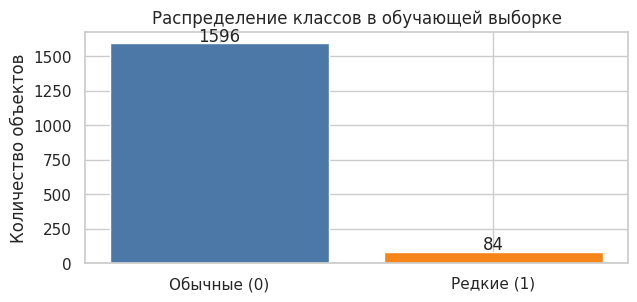

Доля редкого класса в тесте: 0.05


In [2]:
X, y = make_classification(
    n_samples=2400, n_features=10, n_informative=5, n_redundant=2,
    weights=[0.95, 0.05], flip_y=0.0, class_sep=1.0, random_state=SEED
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=SEED
)
counts = pd.Series(y_train).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(['Обычные (0)', 'Редкие (1)'], counts.values, color=['#4C78A8', '#F58518'])
ax.set(title='Распределение классов в обучающей выборке', ylabel='Количество объектов')
for i, v in enumerate(counts.values): ax.text(i, v+15, str(v), ha='center')
plt.show()
print('Доля редкого класса в тесте:', round(y_test.mean(), 3))

Accuracy: 0.95
Recall по редкому классу: 0.0
F1 по редкому классу: 0.0


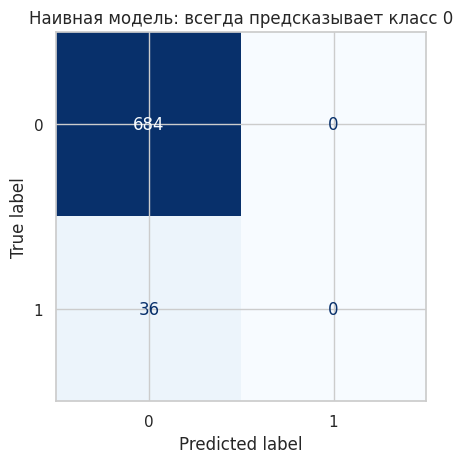

In [3]:
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)
print('Accuracy:', accuracy_score(y_test, dummy_pred))
print('Recall по редкому классу:', recall_score(y_test, dummy_pred, zero_division=0))
print('F1 по редкому классу:', f1_score(y_test, dummy_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, dummy_pred, cmap='Blues', colorbar=False)
plt.title('Наивная модель: всегда предсказывает класс 0')
plt.show()

**Разбор.** Приблизительно 95% accuracy получается просто из-за преобладающего класса. Но *recall положительного класса равен нулю*: ни одного интересующего события модель не находит.

- **Accuracy:** доля правильных ответов вообще.
- **Recall:** доля найденных объектов класса 1 среди всех реальных объектов класса 1.
- **Precision:** доля истинных объектов класса 1 среди тех, которые модель назвала классом 1.
- **Balanced accuracy:** средний recall по двум классам.

**Студентам:** почему нельзя оценивать такой классификатор только по accuracy?

---
# 2. Что делать с дисбалансом: `class_weight="balanced"`


Сравним три модели на **одном и том же тесте**: наивную, обычную логистическую регрессию и регрессию с весами классов.

Взвешивание сильнее штрафует ошибки на редком классе во время обучения. Оно **не гарантирует**, что все метрики вырастут одновременно: часто растёт recall, но снижается precision.

⚠️ Масштабирование включено в `Pipeline`: `StandardScaler` подбирается только по `X_train` — так нет утечки данных с теста.

In [4]:
ordinary = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=SEED))
weighted = make_pipeline(StandardScaler(), LogisticRegression(
    max_iter=2000, class_weight='balanced', random_state=SEED))
ordinary.fit(X_train, y_train)
weighted.fit(X_train, y_train)

def metric_row(name, y_true, pred):
    return dict(Модель=name, Accuracy=accuracy_score(y_true,pred),
                Balanced_accuracy=balanced_accuracy_score(y_true,pred),
                Precision=precision_score(y_true,pred,zero_division=0),
                Recall=recall_score(y_true,pred,zero_division=0),
                F1=f1_score(y_true,pred,zero_division=0))

pred_ord = ordinary.predict(X_test)
pred_weighted = weighted.predict(X_test)
comparison = pd.DataFrame([
    metric_row('Всегда 0', y_test, dummy_pred),
    metric_row('Обычная LR', y_test, pred_ord),
    metric_row('LR + balanced', y_test, pred_weighted),
]).set_index('Модель')
display(comparison.round(3))

,Accuracy,Balanced_accuracy,Precision,Recall,F1
Модель,,,,,
Всегда 0,0.950,0.500,0.000,0.000,0.000
Обычная LR,0.947,0.538,0.375,0.083,0.136
LR + balanced,0.776,0.817,0.166,0.861,0.278


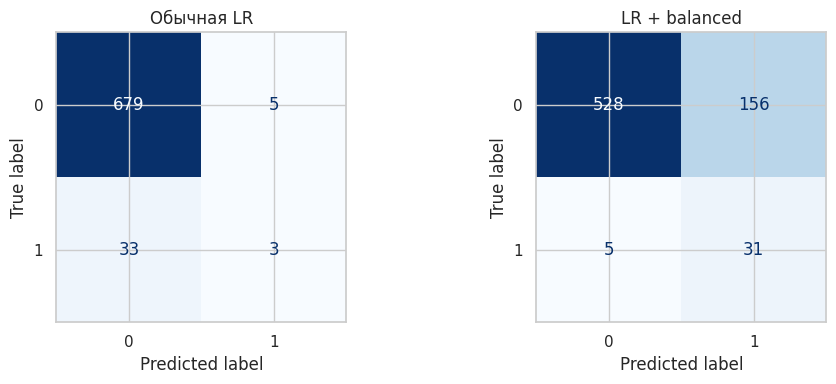

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name, pred in zip(axes, ['Обычная LR', 'LR + balanced'], [pred_ord,pred_weighted]):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, cmap='Blues',
                                             colorbar=False, values_format='d')
    ax.set_title(name)
plt.tight_layout()
plt.show()

**Обсуждение:**
1. Какая модель пропустила меньше редких событий (**FN**)?
2. Какая чаще ошибочно тревожит (**FP**)?
3. Что выбрать для скрининга, а что — для сценария, где ложная тревога дорогая?

> Выбор зависит от стоимости ошибок. `class_weight='balanced'` — не волшебная кнопка «сделать лучше».

### Мини-эксперимент (3 минуты)
Попробуйте заменить `class_weight='balanced'` на `class_weight={0:1, 1:3}` и на `{0:1, 1:10}`. Как меняются FN/FP? Код ниже делает эксперимент автоматически.

In [6]:
rows=[]
for cw in [None, {0:1, 1:3}, {0:1, 1:10}, 'balanced']:
    m=make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight=cw, random_state=SEED))
    m.fit(X_train,y_train)
    p=m.predict(X_test)
    tn,fp,fn,tp=confusion_matrix(y_test,p).ravel()
    rows.append({'Вес класса 1':str(cw),'FP':fp,'FN':fn,
                 'Precision':precision_score(y_test,p,zero_division=0),
                 'Recall':recall_score(y_test,p,zero_division=0)})
display(pd.DataFrame(rows).round(3))

,Вес класса 1,FP,FN,Precision,Recall
0,None,5,33,0.375,0.083
1,"{0: 1, 1: 3}",23,27,0.281,0.250
2,"{0: 1, 1: 10}",90,13,0.204,0.639
3,balanced,156,5,0.166,0.861


---
# 3. Регуляризация: что означает параметр `C`?

Для иллюстрации используем встроенный датасет с числовыми признаками о характеристиках клеток. 

Регуляризация ограничивает коэффициенты модели и помогает уменьшать переобучение.

- **L2** обычно уменьшает абсолютные значения коэффициентов, но редко делает их строго нулевыми.
- **L1** может обнулять часть коэффициентов — получается своего рода отбор признаков.
- В `LogisticRegression` параметр **`C` — обратная величина силы регуляризации**: маленький `C` = сильнее ограничение.

⚠️ Интерпретируем коэффициенты *после стандартизации*. При сильной корреляции признаков коэффициенты могут быть нестабильны.

In [7]:
cancer = load_breast_cancer()
Xc = pd.DataFrame(cancer.data, columns=cancer.feature_names)
yc = cancer.target
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.25, random_state=SEED, stratify=yc
)
print('Признаков:', Xc.shape[1], '| объектов:', Xc.shape[0])
print('Метки sklearn:', dict(enumerate(cancer.target_names)))
print('Здесь интересуемся закономерностями коэффициентов, а не медицинской диагностикой.')

Признаков: 30 | объектов: 569
Метки sklearn: {0: np.str_('malignant'), 1: np.str_('benign')}
Здесь интересуемся закономерностями коэффициентов, а не медицинской диагностикой.


In [8]:
regularization_rows=[]
coefs={}
for penalty in ['l1','l2']:
    for C in [0.01, 0.1, 1, 10]:
        model=make_pipeline(StandardScaler(), LogisticRegression(
            C=C, penalty=penalty, solver='liblinear', max_iter=5000, random_state=SEED))
        model.fit(Xc_train, yc_train)
        weights=model.named_steps['logisticregression'].coef_[0]
        coefs[(penalty,C)]=weights
        regularization_rows.append({'Штраф':penalty,'C':C,
            'Нулевых коэф.':int(np.sum(np.isclose(weights,0,atol=1e-7))),
            '||w||₂':float(np.linalg.norm(weights)),
            'Accuracy train':model.score(Xc_train,yc_train),
            'Accuracy test':model.score(Xc_test,yc_test)})
regularization_df=pd.DataFrame(regularization_rows)
display(regularization_df.round(3))

/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(

,Штраф,C,Нулевых коэф.,||w||₂,Accuracy train,Accuracy test
0,l1,0.01,26,0.493,0.932,0.909
1,l1,0.10,23,2.418,0.984,0.972
2,l1,1.00,14,4.648,0.988,0.993
3,l1,10.00,8,20.285,0.995,0.958
4,l2,0.01,0,0.832,0.974,0.958
5,l2,0.10,0,1.794,0.986,0.986
6,l2,1.00,0,3.535,0.988,0.986
7,l2,10.00,0,8.323,0.991,0.972


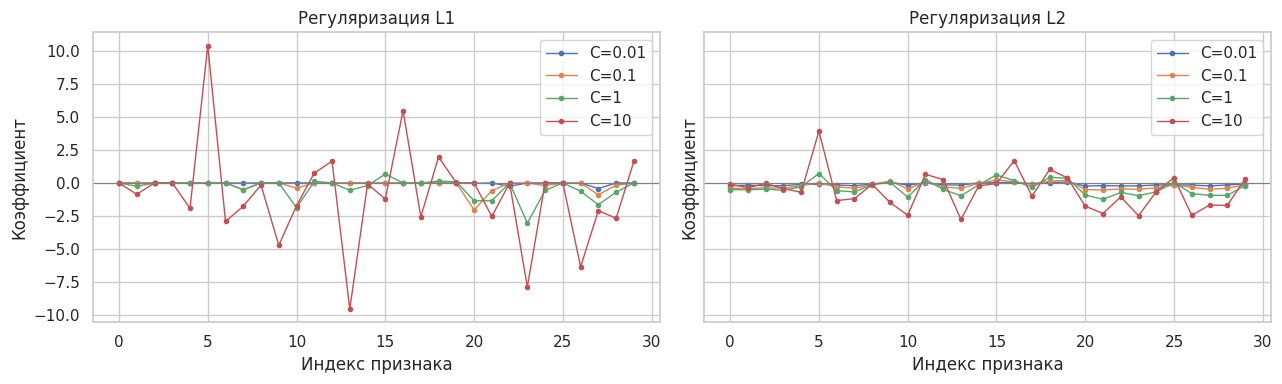

In [9]:
fig, axes=plt.subplots(1,2,figsize=(13,4),sharey=True)
for ax, penalty in zip(axes,['l1','l2']):
    for C in [0.01,0.1,1,10]:
        weights=coefs[(penalty,C)]
        ax.plot(np.arange(len(weights)),weights,marker='.',linewidth=1,label=f'C={C}')
    ax.axhline(0,color='gray',linewidth=0.8)
    ax.set(title=f'Регуляризация {penalty.upper()}',xlabel='Индекс признака',ylabel='Коэффициент')
    ax.legend()
plt.tight_layout()
plt.show()

**Вопросы аудитории:**
- При каком `C` коэффициенты ближе к нулю?
- Почему L1 иногда оставляет лишь несколько признаков?
- Обязательно ли увеличение `C` улучшает качество на тесте? (Нет.)

**Студентам (3 мин):** найдите строку с наибольшей `Accuracy test`. Почему нельзя бесконечно подбирать `C` по одной и той же тестовой выборке? **Ответ:** тест перестаёт быть независимой проверкой; гиперпараметры подбирают на валидации / кросс-валидации, а тест используют в конце.

---
# 4. А если граница между классами не прямая?

Создадим два концентрических кольца. **Прогноз до запуска:** сможет ли логистическая регрессия разделить их прямой линией?

`PolynomialFeatures(degree=2)` добавляет квадраты и попарные произведения исходных признаков. **Модель остаётся линейной по коэффициентам**, но решение в пространстве исходных признаков может иметь кривую границу.

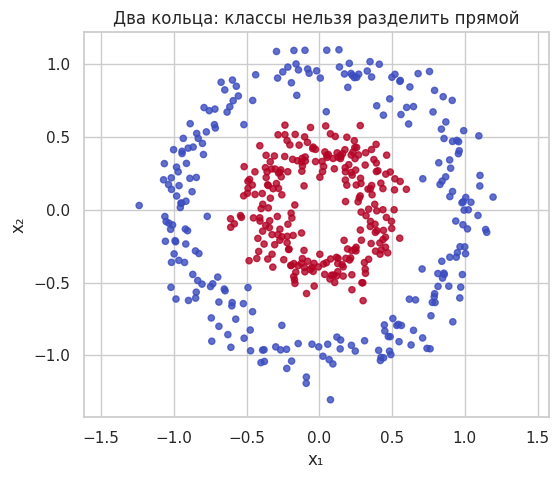

In [10]:
X_circle,y_circle=make_circles(n_samples=700,noise=0.09,factor=0.42,random_state=SEED)
Xci_train,Xci_test,yci_train,yci_test=train_test_split(
    X_circle,y_circle,test_size=0.3,stratify=y_circle,random_state=SEED)
plt.figure(figsize=(6,5))
plt.scatter(Xci_train[:,0],Xci_train[:,1],c=yci_train,cmap='coolwarm',s=20,alpha=.8)
plt.title('Два кольца: классы нельзя разделить прямой')
plt.xlabel('x₁');plt.ylabel('x₂');plt.axis('equal');plt.show()

Тестовая accuracy (без расширения): 0.457
Тестовая accuracy (полином 2): 1.0


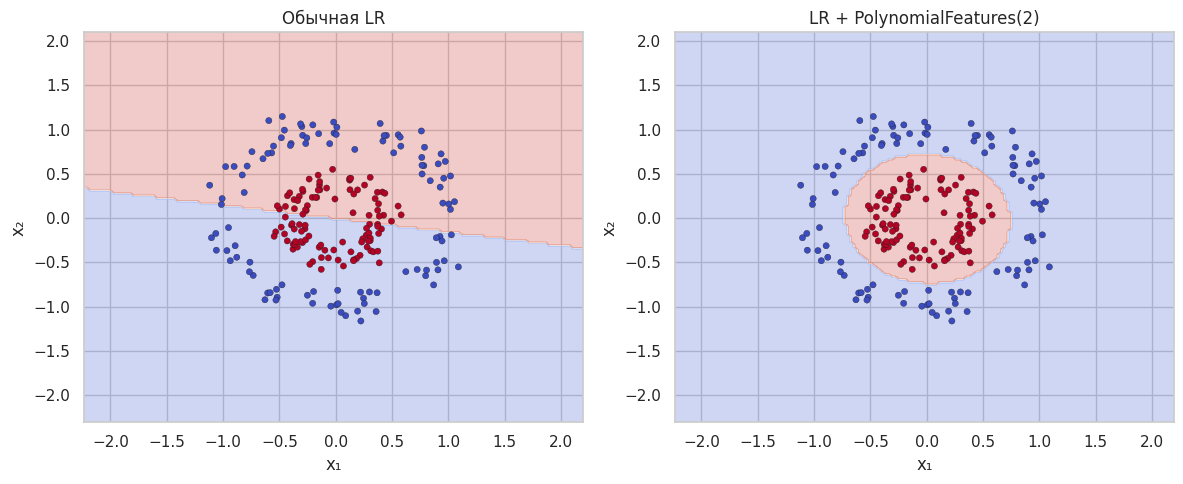

In [11]:
linear_circle=make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000))
poly_circle=make_pipeline(PolynomialFeatures(degree=2,include_bias=False),
                          StandardScaler(),LogisticRegression(max_iter=2000))
linear_circle.fit(Xci_train,yci_train)
poly_circle.fit(Xci_train,yci_train)
print('Тестовая accuracy (без расширения):',round(linear_circle.score(Xci_test,yci_test),3))
print('Тестовая accuracy (полином 2):',round(poly_circle.score(Xci_test,yci_test),3))
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,m,title in zip(axes,[linear_circle,poly_circle],['Обычная LR','LR + PolynomialFeatures(2)']):
    DecisionBoundaryDisplay.from_estimator(m,Xci_train,response_method='predict',ax=ax,
                                           alpha=.27,cmap='coolwarm',grid_resolution=150)
    ax.scatter(Xci_test[:,0],Xci_test[:,1],c=yci_test,cmap='coolwarm',s=20,edgecolor='k',linewidth=.25)
    ax.set(title=title,xlabel='x₁',ylabel='x₂')
plt.tight_layout();plt.show()

**Обсуждение:** мы не заменили алгоритм, а помогли ему новыми признаками. Для двух исходных признаков после `degree=2` получаем `x₁`, `x₂`, `x₁²`, `x₁x₂`, `x₂²`.

**Студентам (3 мин):** замените степень 2 на 1 и на 4. Что происходит с границей и с количеством признаков? Изменение степени лучше оценивать кросс-валидацией, а не подбором по тесту.

In [12]:
for degree in [1,2,4]:
    m=make_pipeline(PolynomialFeatures(degree=degree,include_bias=False),
                    StandardScaler(),LogisticRegression(max_iter=4000))
    m.fit(Xci_train,yci_train)
    print(f'Степень {degree}: новых признаков {m.named_steps["polynomialfeatures"].n_output_features_}, '
          f'accuracy train={m.score(Xci_train,yci_train):.3f}, test={m.score(Xci_test,yci_test):.3f}')

Степень 1: новых признаков 2, accuracy train=0.520, test=0.457
Степень 2: новых признаков 5, accuracy train=0.998, test=1.000
Степень 4: новых признаков 14, accuracy train=0.996, test=1.000


---
# 5. ROC и Precision–Recall: оцениваем модель при всех порогах

Вернёмся к **несбалансированным** данным из первого блока.

- **ROC:** TPR (recall) против FPR при изменении порога.
- **PR-кривая:** precision против recall при изменении порога.
- **ROC-AUC:** площадь под ROC-кривой, характеризует ранжирование классов.
- **Average Precision (AP):** показатель качества PR-кривой (не следует автоматически называть его геометрической площадью под кривой).

При редком положительном классе **PR-кривая часто информативнее**: она сильнее отражает проблему ложноположительных срабатываний среди немногих найденных положительных.

Важно: на случайной модели ориентир AP примерно равен доле положительного класса. У ROC-AUC случайный ориентир — 0.5.

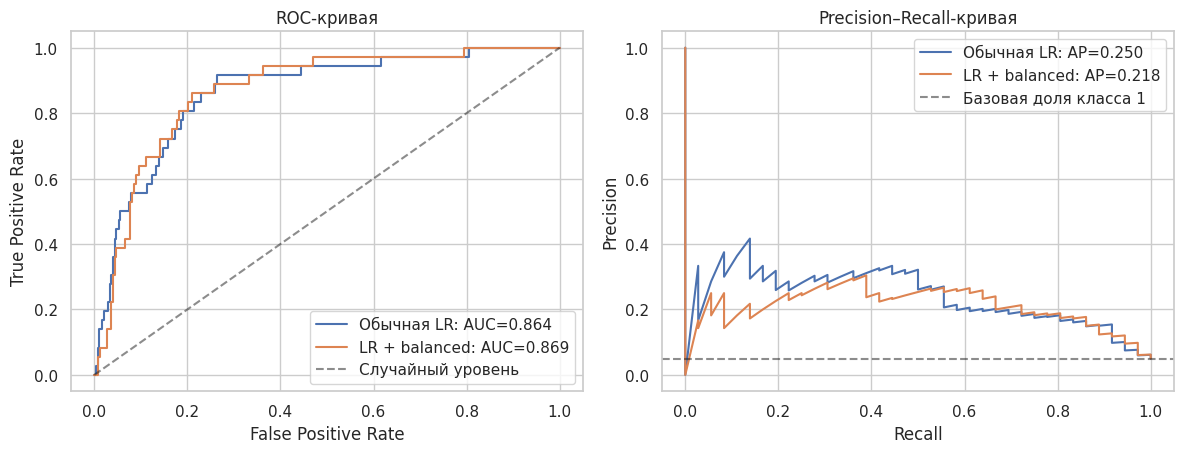

In [13]:
fig,axes=plt.subplots(1,2,figsize=(12,4.7))
for m,label in [(ordinary,'Обычная LR'),(weighted,'LR + balanced')]:
    scores=m.predict_proba(X_test)[:,1]
    fpr,tpr,_=roc_curve(y_test,scores)
    prec,rec,_=precision_recall_curve(y_test,scores)
    axes[0].plot(fpr,tpr,label=f'{label}: AUC={roc_auc_score(y_test,scores):.3f}')
    axes[1].plot(rec,prec,label=f'{label}: AP={average_precision_score(y_test,scores):.3f}')
axes[0].plot([0,1],[0,1],'k--',alpha=.5,label='Случайный уровень')
axes[1].axhline(y_test.mean(),color='k',linestyle='--',alpha=.5,label='Базовая доля класса 1')
axes[0].set(xlabel='False Positive Rate',ylabel='True Positive Rate',title='ROC-кривая')
axes[1].set(xlabel='Recall',ylabel='Precision',title='Precision–Recall-кривая')
for ax in axes: ax.legend(loc='best')
plt.tight_layout();plt.show()

### Эксперимент: сдвигаем порог

Порог меняет **конкретные предсказания и precision/recall/F1**, но не ROC-AUC/AP, вычисленные по фиксированным скоринговым значениям модели. Ниже везде используется одна и та же модель и её вероятности, меняется только правило перехода к классу.

,Порог,TP,FP,FN,TN,Precision,Recall,F1
0,0.1,20,74,16,610,0.213,0.556,0.308
1,0.2,13,30,23,654,0.302,0.361,0.329
2,0.3,7,17,29,667,0.292,0.194,0.233
3,0.5,3,5,33,679,0.375,0.083,0.136
4,0.7,0,2,36,682,0.000,0.000,0.000
5,0.9,0,0,36,684,0.000,0.000,0.000


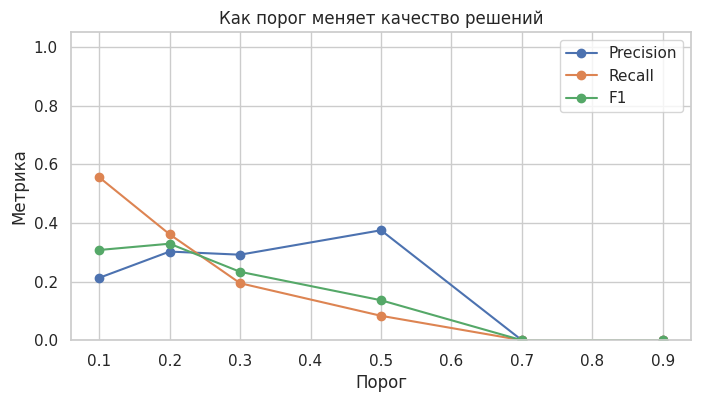

In [14]:
scores=ordinary.predict_proba(X_test)[:,1]
threshold_rows=[]
for t in [0.1,0.2,0.3,0.5,0.7,0.9]:
    pred=(scores>=t).astype(int)
    tn,fp,fn,tp=confusion_matrix(y_test,pred).ravel()
    threshold_rows.append({'Порог':t,'TP':tp,'FP':fp,'FN':fn,'TN':tn,
                           'Precision':precision_score(y_test,pred,zero_division=0),
                           'Recall':recall_score(y_test,pred,zero_division=0),
                           'F1':f1_score(y_test,pred,zero_division=0)})
thr_df=pd.DataFrame(threshold_rows)
display(thr_df.round(3))
plt.figure(figsize=(8,4))
for metric in ['Precision','Recall','F1']:
    plt.plot(thr_df['Порог'],thr_df[metric],marker='o',label=metric)
plt.title('Как порог меняет качество решений');plt.xlabel('Порог');plt.ylabel('Метрика')
plt.ylim(0,1.05);plt.legend();plt.show()

**Вопрос группе:** при поиске редких опасных событий важнее пропустить меньше событий (малый FN) или уменьшить ложные тревоги (малый FP)? Какой порог выбрать — и почему? 

⚠️ Мы *изучаем* пороги на тестовых значениях для наглядности. В реальном проекте порог подбирают на отдельной валидационной выборке, а окончательную оценку проводят на ранее не использованном тесте.

---
# 6. Насколько можно доверять вероятностям?

Представьте: модель 100 раз сказала «вероятность класса 1 около 80%». **Если модель хорошо откалибрована**, среди этих случаев примерно 80 должны действительно относиться к классу 1.

Это **другая задача**, чем просто правильно сортировать объекты по риску. ROC-AUC может быть высоким даже при плохо откалиброванных вероятностях.

Проверим две модели на отдельном синтетическом наборе: логистическую регрессию и `GaussianNB`. Гауссовский наивный Байес здесь включён как *контрастная модель*, чтобы калибровочные кривые было с чем сравнивать.

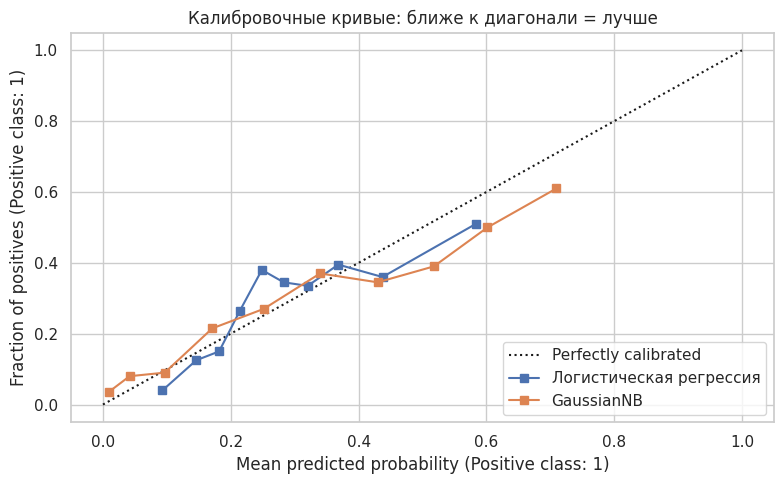

,Brier ↓,Log loss ↓,ROC-AUC ↑
Модель,,,
Логистическая регрессия,0.189,0.557,0.679
GaussianNB,0.179,0.537,0.747


In [15]:
Xcal,ycal=make_classification(n_samples=5000,n_features=14,n_informative=6,
    n_redundant=5,weights=[0.72,0.28],class_sep=0.8,flip_y=0.04,random_state=7)
Xcal_train,Xcal_test,ycal_train,ycal_test=train_test_split(
    Xcal,ycal,test_size=.4,random_state=SEED,stratify=ycal)
models_cal={
    'Логистическая регрессия':make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000)),
    'GaussianNB':GaussianNB()
}
fig,ax=plt.subplots(figsize=(8,5))
cal_rows=[]
for name,model in models_cal.items():
    model.fit(Xcal_train,ycal_train)
    proba=model.predict_proba(Xcal_test)[:,1]
    CalibrationDisplay.from_predictions(ycal_test,proba,n_bins=10,strategy='quantile',
                                         name=name,ax=ax)
    cal_rows.append({'Модель':name,'Brier ↓':brier_score_loss(ycal_test,proba),
                     'Log loss ↓':log_loss(ycal_test,proba),
                     'ROC-AUC ↑':roc_auc_score(ycal_test,proba)})
ax.set_title('Калибровочные кривые: ближе к диагонали = лучше')
plt.tight_layout();plt.show()
display(pd.DataFrame(cal_rows).set_index('Модель').round(3))

**Как читать график?**
- По оси X — средняя предсказанная вероятность в группе объектов.
- По оси Y — фактическая доля положительного класса.
- Диагональ означает идеальную калибровку на этих группах.
- **Brier score** — средняя квадратичная ошибка вероятностных прогнозов; **меньше — лучше**. Для интерпретации учитывайте также базовую частоту класса.

❗ Гладкая красивая линия не гарантирована: калибровка зависит от данных, количества наблюдений и размера групп. Логистическая регрессия **не обязательно** идеально откалибрована.

**Студентам (2 мин):** найдите диапазон вероятностей, где модель завышает риск. Как это видно? (Кривая *ниже* диагонали.)

---
# Финал: ключевые выводы (обсуждение 3 минуты)

| Ситуация | На что смотреть / что попробовать |
|---|---|
| Редкий положительный класс | Recall, Precision, PR-кривая, матрица ошибок |
| Много FN | Цена пропуска, `class_weight`, выбор порога на валидации |
| Слишком большие коэффициенты | Масштабирование, L1/L2, подбор `C` |
| Нелинейное разделение | Создание новых признаков, полиномиальные признаки |
| Хороший ROC-AUC, но странные вероятности | Калибровочная кривая, Brier score |

### Контрольные вопросы
1. Почему модель с 95% accuracy может быть бесполезна?
2. Что произойдёт с регуляризацией при уменьшении `C`?
3. Можем ли мы получить круглую границу решений с логистической регрессией?
4. В чём различие ROC-AUC и precision при конкретном пороге?
5. Что означает хорошо откалиброванная вероятность 0.8?

### Мини-ДЗ (по желанию)
На несбалансированном датасете первого блока сравните 3 значения `C` для обычной и взвешенной логистической регрессии. Используйте кросс-валидацию **только на обучающей выборке**. Выберите модель по F1 или recall (обоснуйте критерий), затем **один раз** оцените на тесте и объясните число FP/FN.